In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
import pandas as pd

df = pd.read_csv("../data/raw/jobs.csv")

In [9]:
df.head()

,job_id,category,job_title,job_description,job_skill_set
0,3902668440,HR,Sr Human Resource Generalist,SUMMARY\nTHE SR. HR GENERALIST PROVIDES HR EXP...,"['employee relations', 'talent acquisition', '..."
1,3905823748,HR,Human Resources Manager,BE PART OF A STELLAR TEAM AT YSB AS THE MANAGE...,"['Talent Acquisition', 'Employee Performance M..."
2,3905854799,HR,Director of Human Resources,OUR CLIENT IS A THRIVING ORGANIZATION OFFERING...,"['Human Resources Management', 'Recruitment', ..."
3,3905834061,HR,Chief Human Resources Officer,JOB TITLE: CHIEF HUMAN RESOURCES OFFICER (CHRO...,"['talent management', 'organizational developm..."
4,3906250451,HR,Human Resources Generalist (Hybrid Role),DESCRIPTION\n\n WHO WE ARE \n\nAVI-SPL IS A DI...,"['Microsoft Office', 'Data analysis', 'Employe..."


In [11]:
df.shape

(1167, 5)

In [12]:
df.columns

Index(['job_id', 'category', 'job_title', 'job_description', 'job_skill_set'], dtype='str')

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1167 entries, 0 to 1166
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   job_id           1167 non-null   int64
 1   category         1167 non-null   str  
 2   job_title        1167 non-null   str  
 3   job_description  1167 non-null   str  
 4   job_skill_set    1167 non-null   str  
dtypes: int64(1), str(4)
memory usage: 4.7 MB


In [14]:
df.isnull().sum()

job_id             0
category           0
job_title          0
job_description    0
job_skill_set      0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["job_skill_set"].iloc[0]

"['employee relations', 'talent acquisition', 'performance management', 'compensation and benefits', 'employment laws and regulations', 'analytical skills', 'employee benefits administration', 'HR policies and procedures', 'recruitment strategies', 'FMLA', 'ADA', 'communication', 'interpersonal skills', 'collaboration', 'influence', 'change management', 'professional development', 'payroll processing', 'job design', 'salary administration', 'human capital management system', 'HR audits and assessments', 'FLSA', 'ERISA', 'EEOC guidelines', 'confidentiality', 'intellectual curiosity']"

In [17]:
type(df["job_skill_set"].iloc[0])

str

In [18]:
df["category"].value_counts()

category
INFORMATION-TECHNOLOGY    240
BUSINESS-DEVELOPMENT      239
FINANCE                   236
SALES                     232
HR                        220
Name: count, dtype: int64

In [20]:
df["job_title"].value_counts().head(20)

job_title
Business Development Manager                  53
Human Resources Generalist                    34
Business Development Representative           33
Human Resources Manager                       28
Information Technology Support Specialist     16
Human Resources Business Partner              15
Finance Manager                               15
Director of Finance                           13
Human Resources Coordinator                   11
Information Technology Project Manager        11
Director of Information Technology            10
Information Technology Project Coordinator    10
Information Technology Manager                10
Human Resources Specialist                     9
Salesperson                                    8
Sales Manager                                  8
Human Resources Assistant                      7
Human Resources Director                       7
Information Technology Specialist              7
Business Development Specialist                7
Name: coun

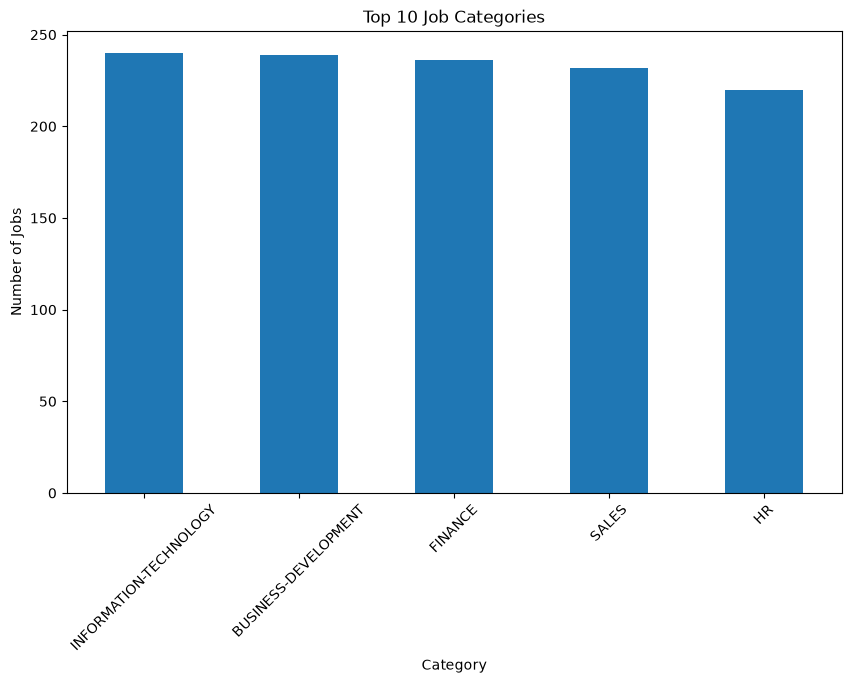

In [24]:
plt.figure(figsize=(10, 6))

df["category"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Job Categories")
plt.xlabel("Category")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45)
plt.show()

In [25]:
df["combined_text"] = (
    df["job_title"] + " " +
    df["category"] + " " +
    df["job_description"] + " " +
    df["job_skill_set"]
)

In [28]:
df[["job_title", "combined_text"]].head()

,job_title,combined_text
0,Sr Human Resource Generalist,Sr Human Resource Generalist HR SUMMARY\nTHE S...
1,Human Resources Manager,Human Resources Manager HR BE PART OF A STELLA...
2,Director of Human Resources,Director of Human Resources HR OUR CLIENT IS A...
3,Chief Human Resources Officer,Chief Human Resources Officer HR JOB TITLE: CH...
4,Human Resources Generalist (Hybrid Role),Human Resources Generalist (Hybrid Role) HR DE...


In [29]:
df["combined_text"].str.len().describe()

count     1167.000000
mean      4175.937446
std       2156.615678
min        358.000000
25%       2507.500000
50%       3841.000000
75%       5365.500000
max      14226.000000
Name: combined_text, dtype: float64

In [30]:
df.to_csv("../data/processed/jobs_cleaned.csv", index=False)

In [31]:
import os

print(os.path.exists("../data/processed/jobs_cleaned.csv"))

True
